# 01 · Citi Bike NYC — EDA, limpieza y preparación de datos

**Objetivo del proyecto:** predecir, para cada estación y cada intervalo de 15 minutos, cuántas bicis **salen** y cuántas **llegan**, separadas por tipo (`classic_bike` / `electric_bike`).

**Este notebook:**
1. Carga todos los CSVs de las carpetas `AAAAMM-citibike-tripdata/`.
2. Diagnostica y **elimina toda fila con algún null o campo vacío**.
3. Limpia registros inválidos (duplicados, duraciones imposibles, coordenadas fuera de NYC, estaciones de prueba).
4. Redondea los tiempos **hacia abajo** a slots de 15 minutos (16:13 → 16:00), es decir, 96 slots por día.
5. Construye la tabla de demanda `estación × slot` con 4 objetivos: `salidas_classic`, `salidas_electric`, `llegadas_classic`, `llegadas_electric`.
6. Descarga el clima histórico de **Open-Meteo** y crea las variables de calendario (día de semana, fin de semana, festivos).
7. EDA visual con seaborn: tendencias, horas pico, estaciones que se vacían o se llenan, impacto del clima y correlaciones.
8. Exporta los archivos `.parquet` que consume el notebook 02 (PyTorch).

**Salidas** (en `data_procesada/`): `estaciones.parquet`, `slots.parquet` (calendario + clima por slot) y `demanda_15min.parquet` (objetivos por estación y slot).

> Requisitos: `pip install pandas pyarrow numpy matplotlib seaborn requests` y, opcionalmente, `holidays`.

## 0. Aceleración opcional con GPU (RAPIDS `cudf.pandas`)
Si tienes RAPIDS instalado (Linux o WSL2 con GPU NVIDIA), `cudf.pandas` acelera pandas en la GPU **sin cambiar el código**. Si no está instalado, el notebook sigue funcionando con pandas normal. Esta celda **debe ejecutarse antes** de importar pandas.

In [1]:
USAR_CUDF = False   # cambia a True si tienes RAPIDS (pip install cudf-cu12 ...)

if USAR_CUDF:
    try:
        get_ipython().run_line_magic('load_ext', 'cudf.pandas')
        print('✅ cudf.pandas activado: pandas se ejecutará en GPU cuando sea posible')
    except Exception as e:
        print('⚠️ cudf.pandas no disponible, se usará pandas en CPU:', e)

## 1. Imports y configuración

In [2]:
import re
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import requests

warnings.filterwarnings('ignore', category=FutureWarning)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (13, 5)
plt.rcParams['figure.dpi'] = 100
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 200)

print('pandas', pd.__version__, '| numpy', np.__version__, '| seaborn', sns.__version__)

pandas 3.0.6 | numpy 2.4.6 | seaborn 0.13.2


In [3]:
# ───────────────────────── CONFIGURACIÓN ─────────────────────────
DATA_DIR   = Path('.')                      # carpeta que CONTIENE las carpetas 2026MM-citibike-tripdata/
PATRON_CSV = '*-citibike-tripdata/*-citibike-tripdata*.csv'      # acepta _1.csv y -part1.csv (abril 2026 viene así)
OUT_DIR    = Path('data_procesada')
OUT_DIR.mkdir(parents=True, exist_ok=True)

FREQ       = '15min'                        # tamaño del slot
SLOTS_DIA  = 96                             # 24 h × 4
TZ         = 'America/New_York'             # Citi Bike reporta hora local de NYC
NYC_LAT, NYC_LON = 40.7128, -74.0060        # punto para el clima (nivel ciudad)

# Caja geográfica amplia de NYC (descarta coordenadas corruptas)
BBOX = dict(lat_min=40.45, lat_max=41.00, lng_min=-74.30, lng_max=-73.65)

MIN_DURACION_S      = 60      # viajes < 60 s que vuelven a la misma estación = re-anclajes, no viajes
MAX_DURACION_H      = 24      # viajes > 24 h = bicis perdidas o errores
MIN_VIAJES_ESTACION = 100     # estaciones con menos actividad total (salidas+llegadas) en el periodo se descartan
TIPOS_BICI          = ['classic_bike', 'electric_bike']

# Estaciones de taller, laboratorio o prueba (no son demanda real)
PATRON_ESTACIONES_PRUEBA = r'(?:\btest\b|lab - nyc|workshop|\bmobile\b|nycbs depot|warehouse|\bdepot\b)'

# Variables de clima a descargar (Open-Meteo, por hora)
VARS_CLIMA = ['temperature_2m', 'apparent_temperature', 'relative_humidity_2m',
              'precipitation', 'rain', 'snowfall', 'cloud_cover',
              'wind_speed_10m', 'weather_code']
CLIMA_CACHE = OUT_DIR / 'clima_horario_raw.parquet'

## 2. Localizar los archivos

In [4]:
import zipfile

RAW_DIR = Path('../data/raw')        # zips descargados de Citi Bike (en .gitignore)

# Si hay un zip en data/raw/ cuya carpeta todavía no está extraída aquí, se extrae (el flujo parte de data/raw/)
for z in sorted(RAW_DIR.glob('*-citibike-tripdata.zip')):
    destino = DATA_DIR / z.stem
    if not any(destino.glob('*.csv')):
        print(f'Extrayendo {z.name} → {destino}/')
        destino.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(z) as zf:
            zf.extractall(destino)

archivos = sorted(DATA_DIR.glob(PATRON_CSV))
assert archivos, f'No se encontraron CSVs con el patrón {PATRON_CSV} dentro de {DATA_DIR.resolve()}'

meses = sorted({re.search(r'(\d{6})-citibike', f.name).group(1) for f in archivos})
esperados = pd.period_range(meses[0], meses[-1], freq='M').strftime('%Y%m').tolist()
faltan = sorted(set(esperados) - set(meses))
assert not faltan, (f'Faltan los meses {faltan}. El calendario es continuo, así que un mes sin archivos '
                    'se contaría como demanda cero en todas las estaciones.')
INICIO = pd.Timestamp(f'{meses[0][:4]}-{meses[0][4:]}-01')
FIN    = pd.Timestamp(f'{meses[-1][:4]}-{meses[-1][4:]}-01') + pd.offsets.MonthBegin(1)   # exclusivo

print(f'{len(archivos)} archivos | meses: {meses}')
print(f'Periodo de análisis: {INICIO:%Y-%m-%d} → {FIN - pd.Timedelta(minutes=15):%Y-%m-%d %H:%M}')
tam_total = 0
for f in archivos:
    tam = f.stat().st_size / 1e6
    tam_total += tam
    print(f'  {f}  ({tam:,.0f} MB)')
print(f'Total: {tam_total:,.0f} MB')


50 archivos | meses: ['202510', '202511', '202512', '202601', '202602', '202603', '202604', '202605', '202606', '202607', '202608', '202609']
Periodo de análisis: 2025-10-01 → 2026-09-30 23:45
  202510-citibike-tripdata/202510-citibike-tripdata_1.csv  (196 MB)
  202510-citibike-tripdata/202510-citibike-tripdata_2.csv  (195 MB)
  202510-citibike-tripdata/202510-citibike-tripdata_3.csv  (194 MB)
  202510-citibike-tripdata/202510-citibike-tripdata_4.csv  (196 MB)
  202510-citibike-tripdata/202510-citibike-tripdata_5.csv  (143 MB)
  202511-citibike-tripdata/202511-citibike-tripdata_1.csv  (196 MB)
  202511-citibike-tripdata/202511-citibike-tripdata_2.csv  (195 MB)
  202511-citibike-tripdata/202511-citibike-tripdata_3.csv  (195 MB)
  202511-citibike-tripdata/202511-citibike-tripdata_4.csv  (82 MB)
  202512-citibike-tripdata/202512-citibike-tripdata_1.csv  (195 MB)
  202512-citibike-tripdata/202512-citibike-tripdata_2.csv  (195 MB)
  202512-citibike-tripdata/202512-citibike-tripdata_3.csv  (

## 3. Carga, diagnóstico de nulls y eliminación
Se procesa **archivo por archivo** para ahorrar memoria. Los textos vacíos o con sólo espacios se convierten en null; después se registra cuántos nulls hay por columna y **se elimina cualquier fila con al menos un null**. También se registra qué tipo de bici se pierde más, porque las e-bikes que terminan fuera de un dock suelen venir sin estación final.

> **Memoria (v3):** con 12 meses (~44 M de viajes) un único DataFrame no cabe cómodamente en memoria.
> Cada archivo pasa por **los mismos pasos de limpieza** (nulls, tipos, duración, coordenadas, estaciones de prueba, periodo) y de él sólo se conserva una representación compacta (~25 bytes por viaje: códigos de estación, slots de 15 min, tipo de bici, día/hora/usuario para el EDA y un hash de `ride_id` para detectar duplicados entre archivos).
> El catálogo de estaciones usa el nombre más frecuente y la **mediana de las medianas mensuales** de las coordenadas (antes, la mediana de todos los puntos).

In [5]:
STR = 'string[pyarrow]'
COLUMNAS = ['ride_id', 'rideable_type', 'started_at', 'ended_at',
            'start_station_name', 'start_station_id', 'end_station_name', 'end_station_id',
            'start_lat', 'start_lng', 'end_lat', 'end_lng', 'member_casual']
COLS_TEXTO = ['ride_id', 'rideable_type', 'started_at', 'ended_at', 'start_station_name',
              'start_station_id', 'end_station_name', 'end_station_id', 'member_casual']
DTYPES = {c: STR for c in COLS_TEXTO}
DTYPES.update({c: 'float32' for c in ['start_lat', 'start_lng', 'end_lat', 'end_lng']})   # float32: ~1 m de precisión, mitad de memoria

paso = pd.Timedelta(FREQ)
vocab = pd.Index([], dtype=STR)          # vocabulario global de station_id → código entero

def codigos_globales(serie):
    # Código entero (estable entre archivos) de cada station_id de la serie
    global vocab
    cat = pd.Categorical(serie)
    nuevos = cat.categories.difference(vocab)
    if len(nuevos):
        vocab = vocab.append(nuevos)
    return vocab.get_indexer(cat.categories)[cat.codes].astype(np.int32)

PASOS = ['Sin nulls ni vacíos', 'Sólo classic_bike / electric_bike', 'ended_at > started_at', f'Duración ≤ {MAX_DURACION_H} h',
         'Coordenadas dentro de NYC', 'Sin estaciones de prueba / taller', 'Inicio dentro del periodo']
conteo = dict.fromkeys(PASOS, 0)
tipos_vistos, nombres_prueba_vistos = {}, set()
reporte_nulos, perdidas_tipo, compactos, nombres_parts, coords_parts = [], [], [], [], []
muestra_slots = None
t_total = time.time()

for f in archivos:
    t0 = time.time()
    d = pd.read_csv(f, usecols=COLUMNAS, dtype=DTYPES)
    n0 = len(d)

    # textos vacíos o con espacios → null
    for c in COLS_TEXTO:
        d[c] = d[c].str.strip().replace('', pd.NA)

    # fechas: lo que no se pueda parsear también cuenta como null
    for c in ['started_at', 'ended_at']:
        d[c] = pd.to_datetime(d[c], format='ISO8601', errors='coerce')

    nulos = d.isna().sum()
    fila_con_nulo = d.isna().any(axis=1)
    reporte_nulos.append({'archivo': f.name, 'filas': n0, 'filas_con_null': int(fila_con_nulo.sum()),
                          **nulos.to_dict()})
    tipos_tot = d['rideable_type'].value_counts(dropna=False)
    tipos_nul = d.loc[fila_con_nulo, 'rideable_type'].value_counts(dropna=False)
    perdidas_tipo.append(pd.DataFrame({'total': tipos_tot, 'con_null': tipos_nul}).fillna(0))

    # ── limpieza (los mismos pasos de antes, aplicados a este archivo) ──
    d = d.loc[~fila_con_nulo]; conteo['Sin nulls ni vacíos'] += len(d)
    for k, v in d['rideable_type'].value_counts().items():
        tipos_vistos[k] = tipos_vistos.get(k, 0) + int(v)
    d = d[d['rideable_type'].isin(TIPOS_BICI)]; conteo['Sólo classic_bike / electric_bike'] += len(d)
    dur = (d['ended_at'] - d['started_at']).dt.total_seconds().to_numpy()
    m = dur > 0;                              d, dur = d[m], dur[m]; conteo['ended_at > started_at'] += len(d)
    m = dur <= MAX_DURACION_H * 3600;         d = d[m];              conteo[f'Duración ≤ {MAX_DURACION_H} h'] += len(d)
    dentro = (d['start_lat'].between(BBOX['lat_min'], BBOX['lat_max']) & d['end_lat'].between(BBOX['lat_min'], BBOX['lat_max']) &
              d['start_lng'].between(BBOX['lng_min'], BBOX['lng_max']) & d['end_lng'].between(BBOX['lng_min'], BBOX['lng_max']))
    d = d[dentro.to_numpy()];                 conteo['Coordenadas dentro de NYC'] += len(d)
    es_prueba_ini = d['start_station_name'].str.contains(PATRON_ESTACIONES_PRUEBA, case=False, regex=True).fillna(False).to_numpy(bool)
    es_prueba_fin = d['end_station_name'].str.contains(PATRON_ESTACIONES_PRUEBA, case=False, regex=True).fillna(False).to_numpy(bool)
    nombres_prueba_vistos |= set(d['start_station_name'][es_prueba_ini]) | set(d['end_station_name'][es_prueba_fin])
    d = d[~(es_prueba_ini | es_prueba_fin)];  conteo['Sin estaciones de prueba / taller'] += len(d)
    d = d[(d['started_at'] >= INICIO) & (d['started_at'] < FIN)]; conteo['Inicio dentro del periodo'] += len(d)

    # ── catálogo: nombres más frecuentes y coordenadas (mediana mensual) por station_id ──
    ini = pd.DataFrame({'station_id': d['start_station_id'], 'name': d['start_station_name'], 'lat': d['start_lat'], 'lng': d['start_lng']})
    fin = pd.DataFrame({'station_id': d['end_station_id'], 'name': d['end_station_name'], 'lat': d['end_lat'], 'lng': d['end_lng']})
    puntos = pd.concat([ini, fin], ignore_index=True)
    nombres_parts.append(puntos.groupby(['station_id', 'name']).size())
    coords_parts.append(puntos.groupby('station_id')[['lat', 'lng']].median())
    del ini, fin, puntos

    # ── slots de 15 min, siempre hacia abajo (16:13 → 16:00) ──
    slot_ini = d['started_at'].dt.floor(FREQ)
    slot_fin = d['ended_at'].dt.floor(FREQ)
    assert (slot_ini.dt.minute % 15 == 0).all() and (slot_ini <= d['started_at']).all()
    if muestra_slots is None:
        muestra_slots = pd.DataFrame({'started_at': d['started_at'], 'slot_salida': slot_ini,
                                      'ended_at': d['ended_at'], 'slot_llegada': slot_fin}).sample(6, random_state=1)

    # ── representación compacta ──
    compactos.append(dict(
        sid_in=codigos_globales(d['start_station_id']), sid_out=codigos_globales(d['end_station_id']),
        t_in=((slot_ini - INICIO) // paso).to_numpy('int64').astype(np.int32),
        t_out=((slot_fin - INICIO) // paso).to_numpy('int64').astype(np.int32),
        tipo=(d['rideable_type'] == 'electric_bike').to_numpy().astype(np.int8),
        dia=(d['started_at'].dt.normalize() - INICIO).dt.days.to_numpy().astype(np.int16),
        hora=d['started_at'].dt.hour.to_numpy().astype(np.int8),
        miembro=(d['member_casual'] == 'member').to_numpy().astype(np.int8),
        hash=pd.util.hash_pandas_object(d['ride_id'], index=False).to_numpy()))
    print(f'{f.name}: {n0:>10,} filas → {len(d):>10,} limpias  ({time.time() - t0:.1f}s)')
    del d, slot_ini, slot_fin

# ── unir archivos y quitar ride_id duplicados (entre archivos, vía hash de 64 bits) ──
CP = {k: np.concatenate([p[k] for p in compactos]) for k in compactos[0]}
del compactos
dup = pd.Series(CP['hash']).duplicated().to_numpy()
conteo['Sin ride_id duplicados'] = int((~dup).sum())
CP = {k: v[~dup] for k, v in CP.items() if k != 'hash'}
del dup

rep = pd.DataFrame(reporte_nulos)
FILAS_ORIGINALES = int(rep['filas'].sum())
N_VIAJES = len(CP['tipo'])
print(f'\nTotal original: {FILAS_ORIGINALES:,} | limpios: {N_VIAJES:,} ({N_VIAJES / FILAS_ORIGINALES:.1%}) | {time.time() - t_total:.0f}s')
print(f'Memoria de la representación compacta: {sum(v.nbytes for v in CP.values()) / 1e9:.2f} GB')


202510-citibike-tripdata_1.csv:  1,000,000 filas →    998,958 limpias  (3.2s)
202510-citibike-tripdata_2.csv:  1,000,000 filas →    994,389 limpias  (3.2s)
202510-citibike-tripdata_3.csv:  1,000,000 filas →    993,587 limpias  (3.2s)
202510-citibike-tripdata_4.csv:  1,000,000 filas →    998,626 limpias  (3.1s)
202510-citibike-tripdata_5.csv:    731,900 filas →    730,020 limpias  (2.3s)
202511-citibike-tripdata_1.csv:  1,000,000 filas →    998,782 limpias  (3.1s)
202511-citibike-tripdata_2.csv:  1,000,000 filas →    995,109 limpias  (3.1s)
202511-citibike-tripdata_3.csv:  1,000,000 filas →    996,019 limpias  (3.1s)
202511-citibike-tripdata_4.csv:    417,052 filas →    416,915 limpias  (1.3s)
202512-citibike-tripdata_1.csv:  1,000,000 filas →    996,862 limpias  (3.2s)
202512-citibike-tripdata_2.csv:  1,000,000 filas →    996,712 limpias  (3.0s)
202512-citibike-tripdata_3.csv:     91,620 filas →     91,530 limpias  (0.3s)
202601-citibike-tripdata_1.csv:  1,000,000 filas →    996,376 li

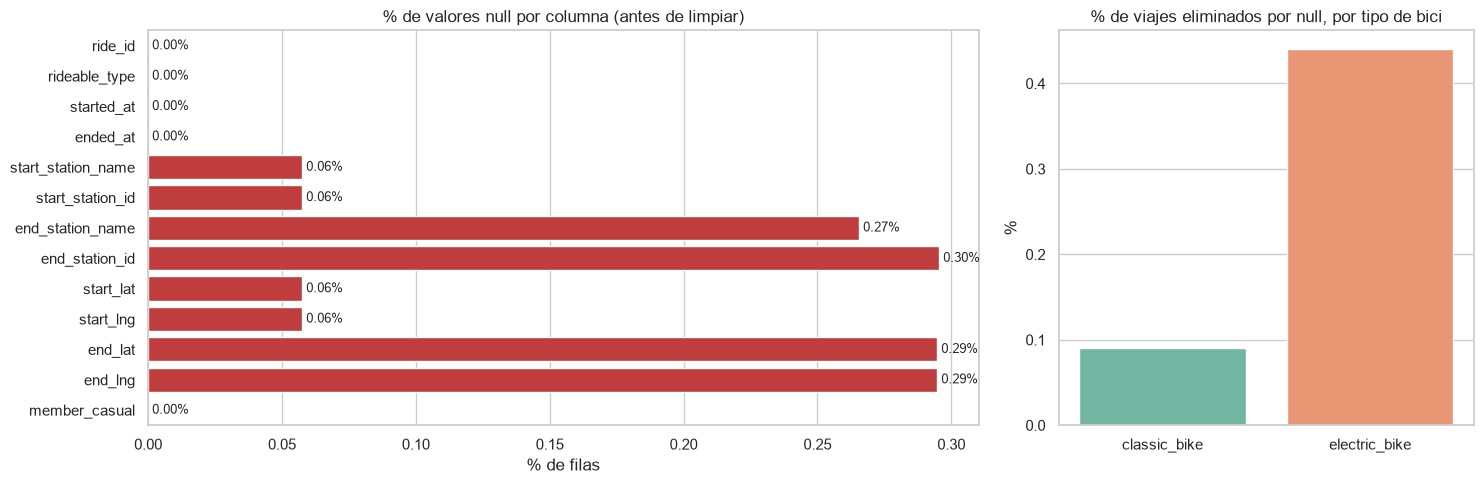

,filas,filas_con_null,pct
archivo,,,
202510-citibike-tripdata_1.csv,1000000,758,0.08
202510-citibike-tripdata_2.csv,1000000,5329,0.53
202510-citibike-tripdata_3.csv,1000000,6367,0.64
202510-citibike-tripdata_4.csv,1000000,1369,0.14
202510-citibike-tripdata_5.csv,731900,1875,0.26
202511-citibike-tripdata_1.csv,1000000,922,0.09
202511-citibike-tripdata_2.csv,1000000,4697,0.47
202511-citibike-tripdata_3.csv,1000000,3978,0.40
202511-citibike-tripdata_4.csv,417052,136,0.03


,total,con_null,% perdido
rideable_type,,,
classic_bike,12563162,10711,0.09
electric_bike,32820943,145376,0.44


In [6]:
# ── Visualización del diagnóstico de nulls ──
nul_col = rep[COLUMNAS].sum() / FILAS_ORIGINALES * 100
perd = pd.concat(perdidas_tipo).groupby(level=0, dropna=False).sum().astype(int)
perd['% perdido'] = (perd['con_null'] / perd['total'] * 100).round(2)

fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={'width_ratios': [2, 1]})
sns.barplot(x=nul_col.values, y=nul_col.index, ax=axes[0], color='tab:red')
axes[0].set(title='% de valores null por columna (antes de limpiar)', xlabel='% de filas', ylabel='')
for i, v in enumerate(nul_col.values):
    axes[0].text(v, i, f' {v:.2f}%', va='center', fontsize=9)

perd_plot = perd.reset_index().rename(columns={'index': 'tipo', 'rideable_type': 'tipo'})
sns.barplot(data=perd_plot, x='tipo', y='% perdido', ax=axes[1], palette='Set2', hue='tipo', legend=False)
axes[1].set(title='% de viajes eliminados por null, por tipo de bici', xlabel='', ylabel='%')
plt.tight_layout(); plt.show()

display(rep.set_index('archivo')[['filas', 'filas_con_null']].assign(
    pct=lambda x: (x.filas_con_null / x.filas * 100).round(2)))
display(perd)

## 4. Limpieza de registros inválidos
Cada paso queda registrado en una bitácora para saber exactamente cuántas filas elimina.

In [7]:
bitacora = ([('Original (todas las filas)', FILAS_ORIGINALES)] + [(p, conteo[p]) for p in PASOS]
            + [('Sin ride_id duplicados', conteo['Sin ride_id duplicados'])])
for paso_, n in bitacora:
    print(f'{paso_:<55} → {n:>12,} filas')
print('Tipos encontrados:', tipos_vistos)
print('Estaciones de prueba detectadas:', sorted(nombres_prueba_vistos))


Original (todas las filas)                              →   45,384,105 filas
Sin nulls ni vacíos                                     →   45,228,018 filas
Sólo classic_bike / electric_bike                       →   45,228,018 filas
ended_at > started_at                                   →   45,227,536 filas
Duración ≤ 24 h                                         →   45,227,252 filas
Coordenadas dentro de NYC                               →   45,227,227 filas
Sin estaciones de prueba / taller                       →   45,227,224 filas
Inicio dentro del periodo                               →   45,226,627 filas
Sin ride_id duplicados                                  →   45,226,146 filas
Tipos encontrados: {'electric_bike': 32675567, 'classic_bike': 12552451}
Estaciones de prueba detectadas: ['Lab - NYC - M']


## 5. Redondeo a slots de 15 minutos (siempre hacia abajo)

In [8]:
display(muestra_slots)
print('✅ Todos los tiempos quedaron en x:00, x:15, x:30 o x:45, redondeados hacia abajo (verificado archivo por archivo)')


✅ Todos los tiempos quedaron en x:00, x:15, x:30 o x:45, redondeados hacia abajo (verificado archivo por archivo)


,started_at,slot_salida,ended_at,slot_llegada
193671,2025-10-01 12:13:19.265,2025-10-01 12:00:00,2025-10-01 12:23:11.631,2025-10-01 12:15:00
668212,2025-10-03 20:12:22.052,2025-10-03 20:00:00,2025-10-03 20:37:17.202,2025-10-03 20:30:00
61385,2025-10-03 17:41:11.459,2025-10-03 17:30:00,2025-10-03 17:42:59.089,2025-10-03 17:30:00
855157,2025-10-06 15:47:11.234,2025-10-06 15:45:00,2025-10-06 15:54:13.975,2025-10-06 15:45:00
36286,2025-10-11 11:59:49.227,2025-10-11 11:45:00,2025-10-11 12:22:25.187,2025-10-11 12:15:00
252304,2025-10-05 15:44:36.185,2025-10-05 15:30:00,2025-10-05 15:50:02.537,2025-10-05 15:45:00


## 6. Catálogo de estaciones
Un mismo `station_id` puede aparecer con nombres o coordenadas ligeramente distintos (las e-bikes reportan GPS). Se usa el nombre más frecuente y la **mediana** de las coordenadas. Después se filtran las estaciones con muy poca actividad.

In [9]:
nombres = (pd.concat(nombres_parts).groupby(level=[0, 1]).sum().rename('n').reset_index()
           .sort_values('n', ascending=False, kind='stable').drop_duplicates('station_id').set_index('station_id')['name'])
coords = pd.concat(coords_parts).groupby(level=0).median()
del nombres_parts, coords_parts

ids_todos = vocab.astype(str)                                                # código → station_id
salidas_tot  = pd.Series(np.bincount(CP['sid_in'],  minlength=len(vocab)), index=ids_todos)
llegadas_tot = pd.Series(np.bincount(CP['sid_out'], minlength=len(vocab)), index=ids_todos)

coords.index = coords.index.astype(str); nombres.index = nombres.index.astype(str)
estaciones = coords.join(nombres)
estaciones['name'] = estaciones['name'].astype(str)
estaciones['salidas_total']  = salidas_tot.reindex(estaciones.index).fillna(0).astype(int)
estaciones['llegadas_total'] = llegadas_tot.reindex(estaciones.index).fillna(0).astype(int)
estaciones['actividad_total'] = estaciones['salidas_total'] + estaciones['llegadas_total']
estaciones.index.name = 'station_id'

n_antes = len(estaciones)
estaciones = estaciones[estaciones['actividad_total'] >= MIN_VIAJES_ESTACION].copy()
print(f'Estaciones encontradas: {n_antes:,} | con ≥ {MIN_VIAJES_ESTACION} viajes: {len(estaciones):,}')

estaciones = estaciones.sort_values('actividad_total', ascending=False, kind='stable').reset_index()
estaciones['station_idx'] = np.arange(len(estaciones), dtype=np.int32)
estaciones['cod'] = vocab.get_indexer(estaciones['station_id'])             # código en el vocabulario global
display(estaciones.head(10))


Estaciones encontradas: 2,627 | con ≥ 100 viajes: 2,515


,station_id,lat,lng,name,salidas_total,llegadas_total,actividad_total,station_idx,cod
0,6140.05,40.741741,-73.994156,W 21 St & 6 Ave,164250,164950,329200,0,1080
1,6233.04,40.746872,-74.008209,Pier 61 at Chelsea Piers,152540,152959,305499,1,1136
2,6331.01,40.749157,-73.991600,W 31 St & 7 Ave,137634,137634,275268,2,1194
3,6492.08,40.752567,-73.996765,9 Ave & W 33 St,135763,136804,272567,3,1271
4,5905.12,40.734547,-73.990738,Broadway & E 14 St,133433,133684,267117,4,978
5,5905.14,40.734814,-73.992088,University Pl & E 14 St,125540,126570,252110,5,979
6,6726.01,40.760300,-73.998840,11 Ave & W 41 St,121873,121898,243771,6,1395
7,6948.10,40.766953,-73.981697,Broadway & W 58 St,126595,116424,243019,7,1497
8,6432.09,40.751873,-73.977707,Park Ave & E 42 St,120048,121108,241156,8,1239
9,6173.08,40.742870,-73.989189,Broadway & W 25 St,118659,119195,237854,9,1097


## 7. Matriz de demanda `estación × slot × objetivo`
Se cuenta con `np.bincount` sobre un arreglo denso de forma `[n_estaciones, n_slots, 4]`, que es mucho más rápido y ligero que hacer pivot sobre millones de filas.

Además, cada estación sólo se considera **desde el primer día hasta el último día en que tuvo actividad**. Así, las estaciones inauguradas o retiradas a mitad del periodo no llenan el entrenamiento de ceros falsos.

In [10]:
TARGETS = ['salidas_classic', 'salidas_electric', 'llegadas_classic', 'llegadas_electric']
slots_ts = pd.date_range(INICIO, FIN, freq=FREQ, inclusive='left').as_unit('ns')
N_SLOTS, N_EST = len(slots_ts), len(estaciones)
mapa_cod = np.full(len(vocab), -1, dtype=np.int64)                  # código global → station_idx (−1 = estación descartada)
mapa_cod[estaciones['cod'].values] = estaciones['station_idx'].values

def indices(cod, t, canal_base):
    s = mapa_cod[cod]
    t = t.astype(np.int64)
    ok = (s >= 0) & (t >= 0) & (t < N_SLOTS)
    c = canal_base + CP['tipo'][ok].astype(np.int64)
    return (s[ok] * N_SLOTS + t[ok]) * 4 + c, ok

def contar(flat, n_est, n_slots, bloques=12):
    # np.bincount sobre bloques de estaciones: evita un arreglo int64 gigante (N_EST × N_SLOTS × 4 × 8 bytes)
    Y = np.zeros((n_est, n_slots, 4), dtype=np.int16)
    corte = np.linspace(0, n_est, bloques + 1).astype(int)
    for a, b in zip(corte[:-1], corte[1:]):
        m = (flat >= a * n_slots * 4) & (flat < b * n_slots * 4)
        Y[a:b] = np.bincount(flat[m] - a * n_slots * 4, minlength=(b - a) * n_slots * 4).reshape(b - a, n_slots, 4)
    return Y

flat_sal, ok_sal = indices(CP['sid_in'],  CP['t_in'],  0)
flat_lle, ok_lle = indices(CP['sid_out'], CP['t_out'], 2)
Y = contar(np.concatenate([flat_sal, flat_lle]), N_EST, N_SLOTS)
print(f'Salidas usadas: {ok_sal.sum():,} | llegadas usadas: {ok_lle.sum():,} '
      f'(las llegadas fuera del periodo o a estaciones descartadas no se cuentan)')
print(f'Matriz Y: {Y.shape}  ({Y.nbytes / 1e6:.0f} MB)')
del flat_sal, flat_lle, ok_sal, ok_lle
CP = {k: CP[k] for k in ['dia', 'tipo', 'hora', 'miembro']}          # lo único que usa el EDA

# ventana activa por estación (días completos)
actividad = np.zeros((N_EST, N_SLOTS), dtype=bool)    # [est, slot], por bloques para no crear un arreglo int64 enorme
for a, b in zip(*(lambda c: (c[:-1], c[1:]))(np.linspace(0, N_EST, 13).astype(int))):
    actividad[a:b] = Y[a:b].sum(axis=2) > 0
primero = actividad.argmax(axis=1)
ultimo  = N_SLOTS - 1 - actividad[:, ::-1].argmax(axis=1)
primer_slot = (primero // SLOTS_DIA) * SLOTS_DIA
ultimo_slot = (ultimo // SLOTS_DIA + 1) * SLOTS_DIA   # exclusivo
rango = np.arange(N_SLOTS)
mascara_activa = (rango[None, :] >= primer_slot[:, None]) & (rango[None, :] < ultimo_slot[:, None])
del actividad
estaciones['primer_dia'] = slots_ts[primer_slot].normalize()
estaciones['ultimo_dia'] = slots_ts[ultimo_slot - 1].normalize()
estaciones['dias_activa'] = (ultimo_slot - primer_slot) // SLOTS_DIA
print(f'Estaciones activas todo el periodo: {(estaciones.dias_activa == N_SLOTS // SLOTS_DIA).sum():,} de {N_EST:,}')


Salidas usadas: 45,225,710 | llegadas usadas: 45,223,604 (las llegadas fuera del periodo o a estaciones descartadas no se cuentan)
Matriz Y: (2515, 35040, 4)  (705 MB)
Estaciones activas todo el periodo: 2,059 de 2,515


In [11]:
# Tabla larga para el modelo: una fila por (estación, slot) dentro de su ventana activa.
# Se llena por bloques de estaciones sobre arreglos preasignados (con ~90 M de filas, np.nonzero de una vez no cabe cómodo).
n_filas = int(mascara_activa.sum())
cols = {'station_idx': np.empty(n_filas, np.int32), 'slot_idx': np.empty(n_filas, np.int32),
        **{nombre: np.empty(n_filas, np.int16) for nombre in TARGETS}}
pos = 0
for blk in np.array_split(np.arange(N_EST), 12):
    s_loc, t_idx = np.nonzero(mascara_activa[blk])
    s_idx = blk[s_loc]
    n = len(s_idx)
    cols['station_idx'][pos:pos + n] = s_idx
    cols['slot_idx'][pos:pos + n] = t_idx
    for k, nombre in enumerate(TARGETS):
        cols[nombre][pos:pos + n] = Y[s_idx, t_idx, k]
    pos += n
demanda = pd.DataFrame(cols, copy=False)
del cols
demanda['salidas_total']  = (demanda['salidas_classic'] + demanda['salidas_electric']).astype(np.int16)
demanda['llegadas_total'] = (demanda['llegadas_classic'] + demanda['llegadas_electric']).astype(np.int16)

print(f'Filas (estación × slot activo): {len(demanda):,}')
print(f'% de filas con 0 salidas: {(demanda.salidas_total == 0).mean():.1%} | '
      f'con 0 llegadas: {(demanda.llegadas_total == 0).mean():.1%}')
display(demanda[TARGETS + ['salidas_total', 'llegadas_total']].describe().T)

Filas (estación × slot activo): 81,158,880
% de filas con 0 salidas: 74.9% | con 0 llegadas: 74.9%


,count,mean,std,min,25%,50%,75%,max
salidas_classic,81158880.0,0.154656,0.560972,0.0,0.0,0.0,0.0,40.0
salidas_electric,81158880.0,0.402593,1.087652,0.0,0.0,0.0,0.0,60.0
llegadas_classic,81158880.0,0.154650,0.548629,0.0,0.0,0.0,0.0,37.0
llegadas_electric,81158880.0,0.402573,1.082274,0.0,0.0,0.0,0.0,48.0
salidas_total,81158880.0,0.557249,1.419457,0.0,0.0,0.0,1.0,74.0
llegadas_total,81158880.0,0.557223,1.424337,0.0,0.0,0.0,1.0,72.0


## 8. Clima histórico (Open-Meteo) y calendario
- Se usa la **API de archivo** de Open-Meteo; si faltan horas recientes, se completan con la API *historical forecast*.
- Detalle importante: en Open-Meteo, la `precipitation` marcada a las 17:00 es la acumulada **entre 16:00 y 17:00**. Por eso las variables acumuladas se desplazan una hora, de modo que el slot 16:15 reciba la lluvia de 16:00–17:00.
- Las variables continuas se interpolan de hora a 15 minutos.
- La descarga se guarda en caché para no repetirla.

In [12]:
def _pedir_open_meteo(url, inicio, fin):
    params = dict(latitude=NYC_LAT, longitude=NYC_LON, start_date=f'{inicio:%Y-%m-%d}', end_date=f'{fin:%Y-%m-%d}',
                  hourly=','.join(VARS_CLIMA), timezone=TZ, wind_speed_unit='kmh')
    r = requests.get(url, params=params, timeout=60)
    r.raise_for_status()
    h = pd.DataFrame(r.json()['hourly'])
    h['time'] = pd.to_datetime(h['time'])
    return h.set_index('time')

def descargar_clima(inicio, fin_exclusivo):
    # Clima horario del periodo. Si ya hay caché, sólo se piden los tramos que faltan y se conserva lo cacheado
    # (los datos de archivo pueden revisarse con el tiempo; así el clima ya usado para entrenar no cambia).
    URL_ARCHIVO = 'https://archive-api.open-meteo.com/v1/archive'
    URL_HIST    = 'https://historical-forecast-api.open-meteo.com/v1/forecast'
    h = None
    if CLIMA_CACHE.exists():
        h = pd.read_parquet(CLIMA_CACHE); h['time'] = pd.to_datetime(h['time']); h = h.set_index('time').sort_index()
        print(f'Caché de clima: {h.index.min():%Y-%m-%d} → {h.index.max():%Y-%m-%d} ({len(h):,} horas)')
    tramos = []   # incluye un día extra al final para poder desplazar la lluvia una hora
    if h is None:
        tramos.append((inicio, fin_exclusivo))
    else:
        if inicio < h.index.min().normalize():
            tramos.append((inicio, h.index.min().normalize()))
        if fin_exclusivo > h.index.max().normalize():
            tramos.append((h.index.max().normalize(), fin_exclusivo))
    for a, b in tramos:
        print(f'Descargando clima {a:%Y-%m-%d} → {b:%Y-%m-%d} ...')
        nuevo = _pedir_open_meteo(URL_ARCHIVO, a, b)
        if nuevo.isna().any().any():
            print('Completando horas faltantes con historical-forecast API...')
            nuevo = nuevo.combine_first(_pedir_open_meteo(URL_HIST, a, b))
        h = nuevo if h is None else h.combine_first(nuevo)       # lo ya cacheado tiene prioridad
    if tramos:
        h = h.sort_index()
        h.reset_index().to_parquet(CLIMA_CACHE, index=False)
        print(f'Clima guardado: {len(h):,} horas → {CLIMA_CACHE}')
    assert h.index.min() <= inicio and h.index.max() >= fin_exclusivo, 'El clima no cubre el periodo completo'
    return h.reset_index()

def clima_a_15min(h, slots_index):
    # Convierte el clima horario de Open-Meteo a slots de 15 minutos
    h = h.copy()
    h['time'] = pd.to_datetime(h['time'])
    h = h.set_index('time').sort_index()
    acumuladas = ['precipitation', 'rain', 'snowfall']
    h[acumuladas] = h[acumuladas].shift(-1)          # valor de las 17:00 = lluvia de 16:00-17:00
    idx = h.index.union(slots_index)
    h = h.reindex(idx)
    continuas = ['temperature_2m', 'apparent_temperature', 'relative_humidity_2m', 'cloud_cover', 'wind_speed_10m']
    h[continuas] = h[continuas].interpolate(method='time', limit_direction='both')
    h[acumuladas + ['weather_code']] = h[acumuladas + ['weather_code']].ffill().bfill()
    return h.reindex(slots_index)

clima_h = descargar_clima(INICIO, FIN)
clima15 = clima_a_15min(clima_h, slots_ts)
print('Nulls en clima 15 min:', int(clima15.isna().sum().sum()))
display(clima15.describe().T.round(2))

Caché de clima: 2025-10-01 → 2026-10-01 (8,784 horas)
Nulls en clima 15 min: 0


,count,mean,std,min,25%,50%,75%,max
temperature_2m,35040.0,12.29,11.36,-18.3,2.92,13.02,21.88,40.70
apparent_temperature,35040.0,10.63,13.74,-24.6,-0.80,10.65,23.08,44.50
relative_humidity_2m,35040.0,67.02,18.49,14.0,53.50,68.00,82.00,100.00
precipitation,35040.0,0.15,0.66,0.0,0.00,0.00,0.00,15.00
rain,35040.0,0.14,0.65,0.0,0.00,0.00,0.00,15.00
snowfall,35040.0,0.01,0.10,0.0,0.00,0.00,0.00,2.45
cloud_cover,35040.0,57.04,41.37,0.0,9.50,69.00,100.00,100.00
wind_speed_10m,35040.0,9.93,5.24,0.0,6.00,9.25,13.10,33.10
weather_code,35040.0,10.15,20.28,0.0,0.00,2.00,3.00,75.00


In [13]:
def festivos_nyc(anios):
    # Festivos FEDERALES de EE. UU. (con sus días observados), igual que la API del dashboard (ui/src/lib/calendar.ts).
    # No se usa state='NY': agrega Election Day, Lincoln's Birthday y Susan B. Anthony Day, que el dashboard no marca.
    try:
        import holidays
        h = holidays.US(years=list(anios))
        return {pd.Timestamp(d): n for d, n in h.items()}
    except ImportError:
        fijos = {
            '2025-01-01': "New Year's Day", '2025-01-20': 'MLK Day', '2025-02-17': "Presidents' Day",
            '2025-05-26': 'Memorial Day', '2025-06-19': 'Juneteenth', '2025-07-04': 'Independence Day',
            '2025-09-01': 'Labor Day', '2025-10-13': 'Columbus Day', '2025-11-11': 'Veterans Day',
            '2025-11-27': 'Thanksgiving', '2025-12-25': 'Christmas',
            '2026-01-01': "New Year's Day", '2026-01-19': 'MLK Day', '2026-02-16': "Presidents' Day",
            '2026-05-25': 'Memorial Day', '2026-06-19': 'Juneteenth', '2026-07-03': 'Independence Day (observed)',
            '2026-07-04': 'Independence Day', '2026-09-07': 'Labor Day', '2026-10-12': 'Columbus Day',
            '2026-11-11': 'Veterans Day', '2026-11-26': 'Thanksgiving', '2026-12-25': 'Christmas',
            '2027-01-01': "New Year's Day", '2027-01-18': 'MLK Day', '2027-02-15': "Presidents' Day",
            '2027-05-31': 'Memorial Day', '2027-06-18': 'Juneteenth (observed)', '2027-07-05': 'Independence Day (observed)',
            '2027-09-06': 'Labor Day', '2027-10-11': 'Columbus Day', '2027-11-11': 'Veterans Day',
            '2027-11-25': 'Thanksgiving', '2027-12-24': 'Christmas (observed)',
        }
        return {pd.Timestamp(k): v for k, v in fijos.items()}

FESTIVOS = festivos_nyc(range(INICIO.year, FIN.year + 1))
print('Festivos en el periodo:', {f'{k:%Y-%m-%d}': v for k, v in FESTIVOS.items() if INICIO <= k < FIN})

slots = pd.DataFrame({'slot_idx': np.arange(N_SLOTS, dtype=np.int32), 'timestamp': slots_ts})
slots['fecha']        = slots['timestamp'].dt.normalize()
slots['hora']         = slots['timestamp'].dt.hour
slots['minuto']       = slots['timestamp'].dt.minute
slots['slot_dia']     = (slots['hora'] * 4 + slots['minuto'] // 15).astype(np.int16)   # 0..95
slots['dia_semana']   = slots['timestamp'].dt.dayofweek.astype(np.int16)              # 0=lunes
slots['es_fin_semana'] = (slots['dia_semana'] >= 5).astype(np.int8)
slots['es_festivo']   = slots['fecha'].isin(list(FESTIVOS)).astype(np.int8)
slots['dia_libre']    = ((slots['es_fin_semana'] == 1) | (slots['es_festivo'] == 1)).astype(np.int8)
slots['slot_sin'] = np.sin(2 * np.pi * slots['slot_dia'] / SLOTS_DIA)
slots['slot_cos'] = np.cos(2 * np.pi * slots['slot_dia'] / SLOTS_DIA)
slots['dow_sin']  = np.sin(2 * np.pi * slots['dia_semana'] / 7)
slots['dow_cos']  = np.cos(2 * np.pi * slots['dia_semana'] / 7)
for c in VARS_CLIMA:
    slots[c] = clima15[c].values.astype(np.float32)
slots['llueve'] = (slots['precipitation'] >= 0.1).astype(np.int8)
display(slots.head())

Festivos en el periodo: {'2025-11-27': 'Thanksgiving Day', '2025-12-25': 'Christmas Day', '2025-10-13': 'Columbus Day', '2025-11-11': 'Veterans Day', '2026-01-01': "New Year's Day", '2026-05-25': 'Memorial Day', '2026-06-19': 'Juneteenth National Independence Day', '2026-07-04': 'Independence Day', '2026-07-03': 'Independence Day (observed)', '2026-09-07': 'Labor Day', '2026-01-19': 'Martin Luther King Jr. Day', '2026-02-16': "Washington's Birthday"}


,slot_idx,timestamp,fecha,hora,minuto,slot_dia,dia_semana,es_fin_semana,es_festivo,dia_libre,slot_sin,slot_cos,dow_sin,dow_cos,temperature_2m,apparent_temperature,relative_humidity_2m,precipitation,rain,snowfall,cloud_cover,wind_speed_10m,weather_code,llueve
0,0,2025-10-01 00:00:00,2025-10-01,0,0,0,2,0,0,0,0.000000,1.000000,0.974928,-0.222521,18.200001,16.100,56.0,0.0,0.0,0.0,30.00,12.50,1.0,0
1,1,2025-10-01 00:15:00,2025-10-01,0,15,1,2,0,0,0,0.065403,0.997859,0.974928,-0.222521,17.950001,15.825,57.0,0.0,0.0,0.0,33.25,12.85,1.0,0
2,2,2025-10-01 00:30:00,2025-10-01,0,30,2,2,0,0,0,0.130526,0.991445,0.974928,-0.222521,17.700001,15.550,58.0,0.0,0.0,0.0,36.50,13.20,1.0,0
3,3,2025-10-01 00:45:00,2025-10-01,0,45,3,2,0,0,0,0.195090,0.980785,0.974928,-0.222521,17.450001,15.275,59.0,0.0,0.0,0.0,39.75,13.55,1.0,0
4,4,2025-10-01 01:00:00,2025-10-01,1,0,4,2,0,0,0,0.258819,0.965926,0.974928,-0.222521,17.200001,15.000,60.0,0.0,0.0,0.0,43.00,13.90,1.0,0


## 9. EDA visual
### 9.1 Tendencia diaria por tipo de bici

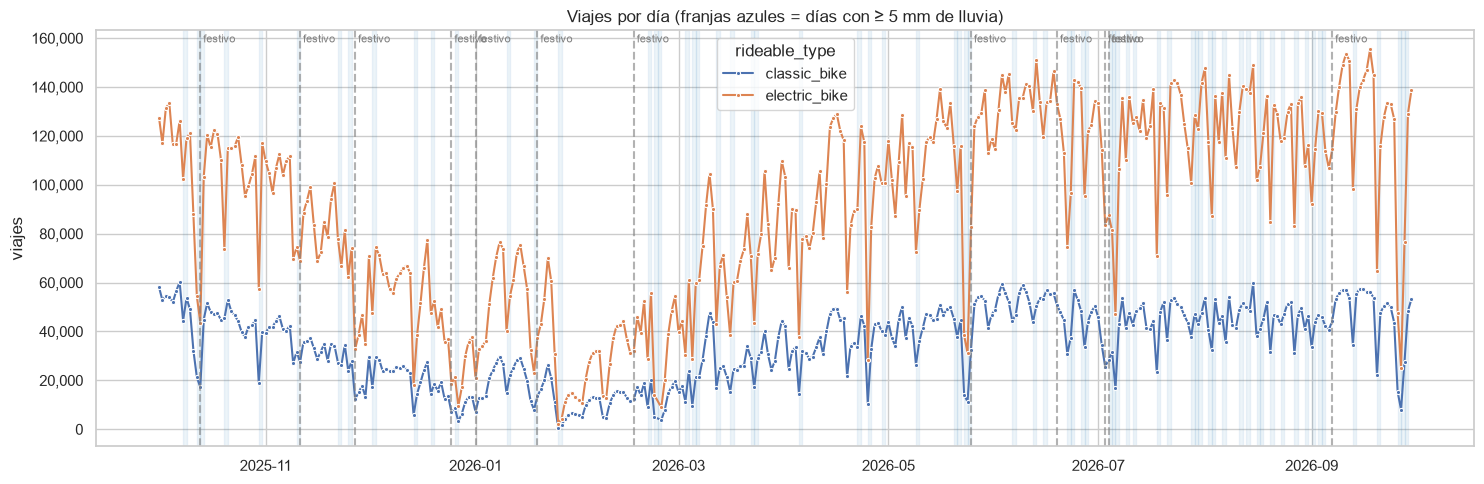

In [14]:
diario = (pd.DataFrame({'fecha': INICIO + pd.to_timedelta(CP['dia'].astype(np.int64), unit='D'),
                        'rideable_type': np.where(CP['tipo'] == 1, 'electric_bike', 'classic_bike')})
          .groupby(['fecha', 'rideable_type']).size().rename('viajes').reset_index())
fig, ax = plt.subplots(figsize=(15, 5))
sns.lineplot(data=diario, x='fecha', y='viajes', hue='rideable_type', marker='o', markersize=3, ax=ax)
for f in [k for k in FESTIVOS if INICIO <= k < FIN]:
    ax.axvline(f, color='gray', ls='--', alpha=.6); ax.text(f, ax.get_ylim()[1] * .97, ' festivo', fontsize=8, color='gray')
lluvia_dia = slots.groupby('fecha')['precipitation'].sum() / 4
dias_lluvia = lluvia_dia[lluvia_dia >= 5].index
for f in dias_lluvia:
    ax.axvspan(f, f + pd.Timedelta(days=1), color='tab:blue', alpha=.08)
ax.set(title='Viajes por día (franjas azules = días con ≥ 5 mm de lluvia)', xlabel='', ylabel='viajes')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
plt.tight_layout(); plt.show()


### 9.2 Patrón semanal: día × hora (salidas de toda la ciudad)

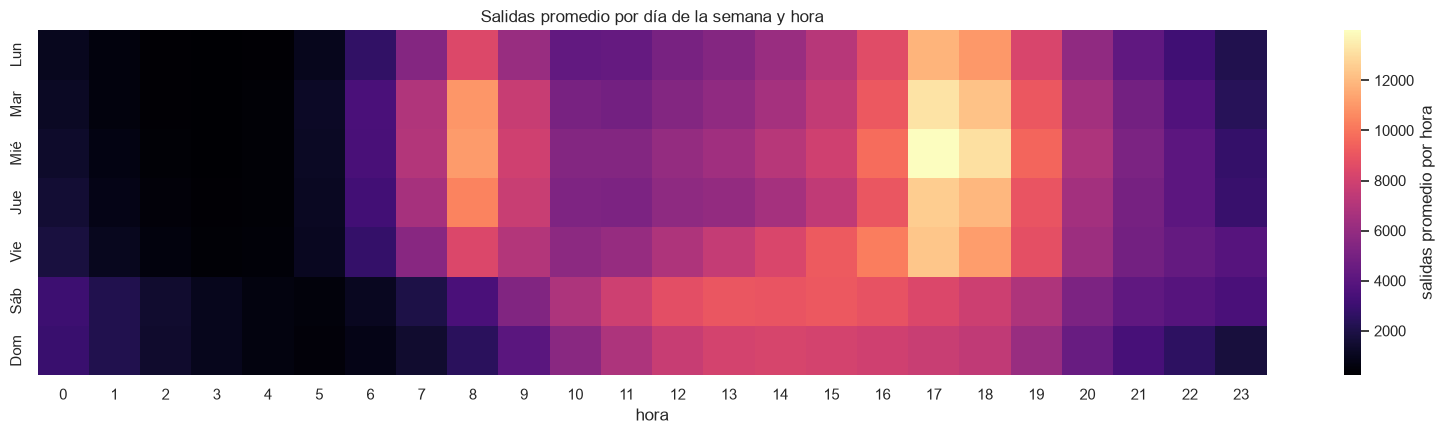

In [15]:
total_slot = Y.sum(axis=0)                 # [slot, 4] totales de la ciudad
ciudad = slots[['timestamp', 'fecha', 'hora', 'slot_dia', 'dia_semana', 'dia_libre', 'es_festivo'] + VARS_CLIMA + ['llueve']].copy()
for k, n in enumerate(TARGETS):
    ciudad[n] = total_slot[:, k]
ciudad['salidas'] = ciudad['salidas_classic'] + ciudad['salidas_electric']
ciudad['llegadas'] = ciudad['llegadas_classic'] + ciudad['llegadas_electric']

DIAS = ['Lun', 'Mar', 'Mié', 'Jue', 'Vie', 'Sáb', 'Dom']
n_dias = ciudad.groupby('dia_semana')['fecha'].nunique()
piv = ciudad.groupby(['dia_semana', 'hora'])['salidas'].sum().unstack() .div(n_dias, axis=0)
piv.index = DIAS
fig, ax = plt.subplots(figsize=(16, 4.5))
sns.heatmap(piv, cmap='magma', ax=ax, cbar_kws={'label': 'salidas promedio por hora'})
ax.set(title='Salidas promedio por día de la semana y hora', xlabel='hora', ylabel='')
plt.tight_layout(); plt.show()

### 9.3 Perfil de los 96 slots: laborable vs día libre

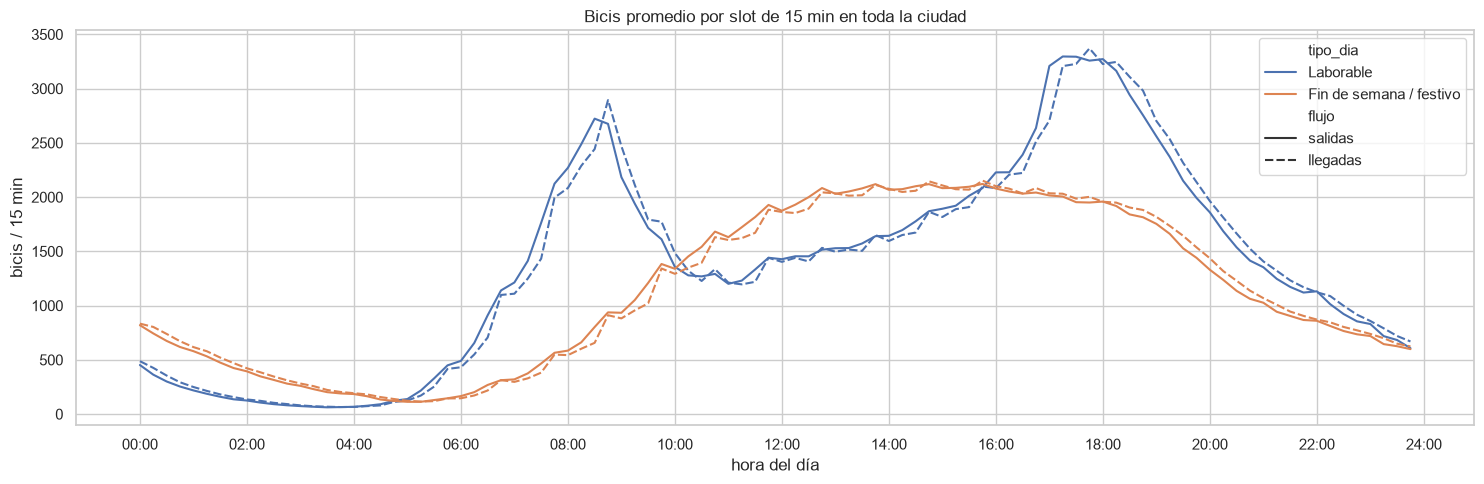

In [16]:
perfil = ciudad.groupby(['dia_libre', 'slot_dia'])[['salidas', 'llegadas']].mean().reset_index()
perfil['tipo_dia'] = perfil['dia_libre'].map({0: 'Laborable', 1: 'Fin de semana / festivo'})
perfil = perfil.melt(id_vars=['tipo_dia', 'slot_dia'], value_vars=['salidas', 'llegadas'], var_name='flujo', value_name='bicis')
fig, ax = plt.subplots(figsize=(15, 5))
sns.lineplot(data=perfil, x='slot_dia', y='bicis', hue='tipo_dia', style='flujo', ax=ax)
ax.set_xticks(range(0, 97, 8)); ax.set_xticklabels([f'{h:02d}:00' for h in range(0, 25, 2)])
ax.set(title='Bicis promedio por slot de 15 min en toda la ciudad', xlabel='hora del día', ylabel='bicis / 15 min')
plt.tight_layout(); plt.show()

### 9.4 Classic vs electric a lo largo del día

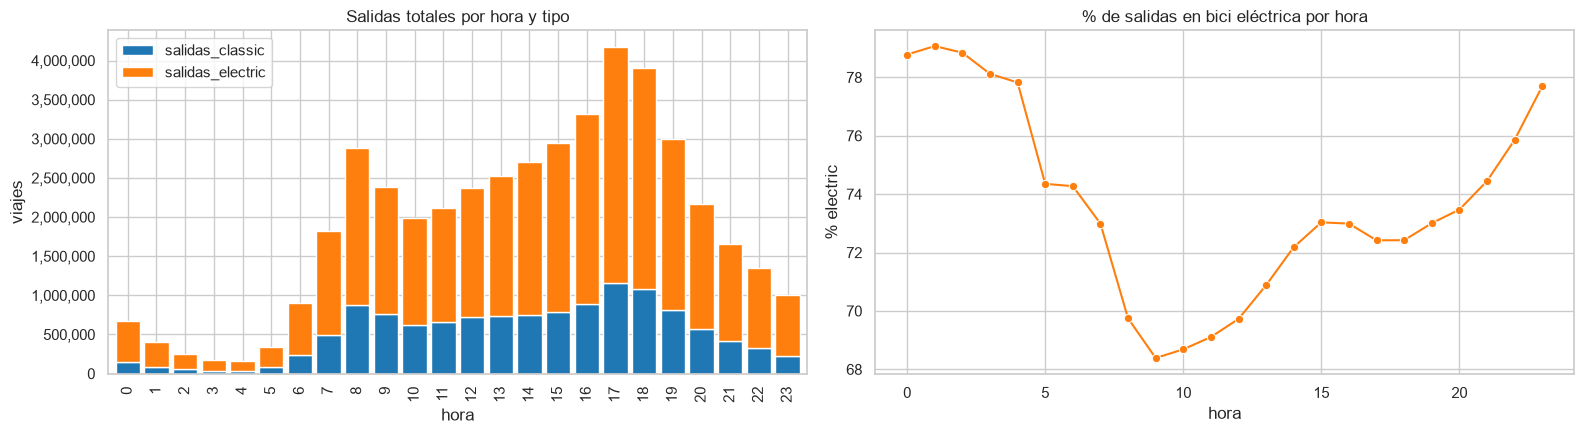

In [17]:
mix = ciudad.groupby('hora')[['salidas_classic', 'salidas_electric']].sum()
mix_pct = mix.div(mix.sum(axis=1), axis=0) * 100
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
mix.plot(kind='bar', stacked=True, ax=axes[0], color=['tab:blue', 'tab:orange'], width=.85)
axes[0].set(title='Salidas totales por hora y tipo', xlabel='hora', ylabel='viajes')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
sns.lineplot(x=mix_pct.index, y=mix_pct['salidas_electric'], marker='o', ax=axes[1], color='tab:orange')
axes[1].set(title='% de salidas en bici eléctrica por hora', xlabel='hora', ylabel='% electric')
plt.tight_layout(); plt.show()

### 9.5 Estaciones con más movimiento

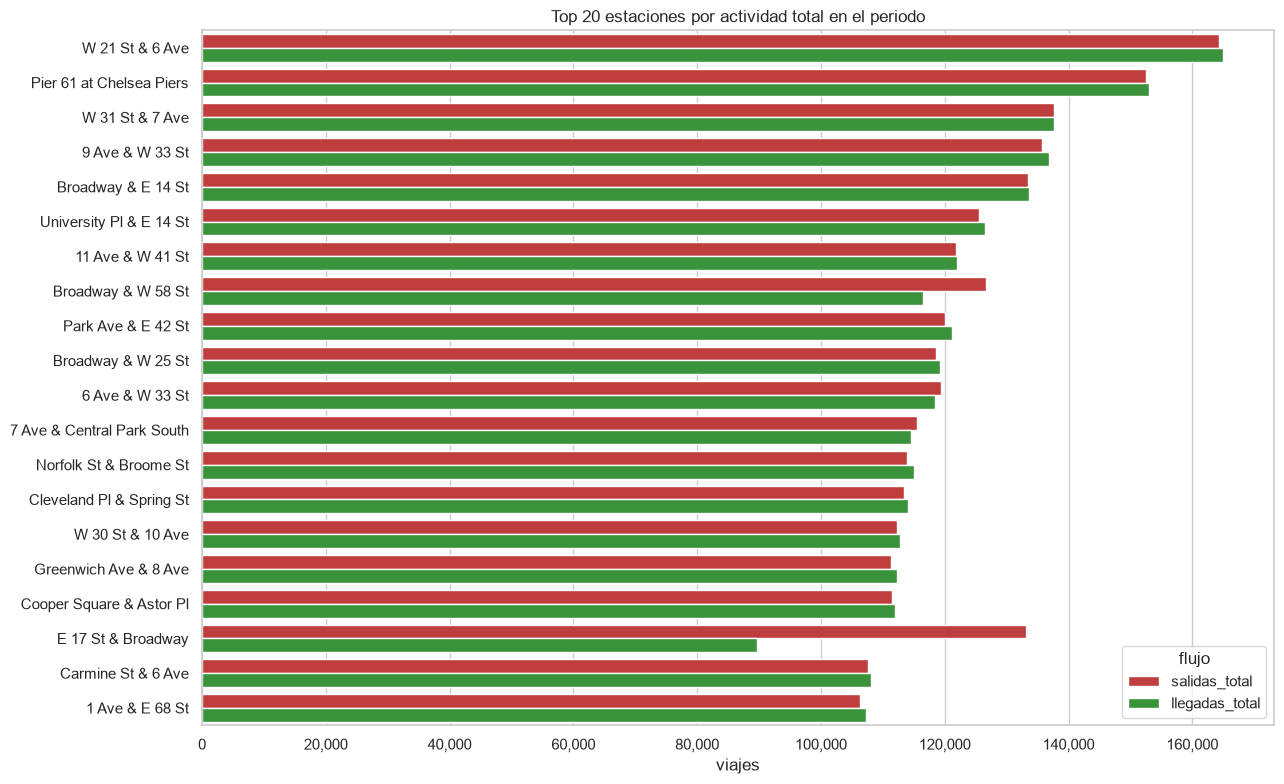

In [18]:
top = estaciones.head(20).copy()
top['nombre'] = top['name'].str.slice(0, 38)
top_m = top.melt(id_vars='nombre', value_vars=['salidas_total', 'llegadas_total'], var_name='flujo', value_name='viajes')
fig, ax = plt.subplots(figsize=(13, 8))
sns.barplot(data=top_m, y='nombre', x='viajes', hue='flujo', ax=ax, palette=['tab:red', 'tab:green'])
ax.set(title='Top 20 estaciones por actividad total en el periodo', ylabel='', xlabel='viajes')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
plt.tight_layout(); plt.show()

### 9.6 Flujo neto: ¿qué estaciones se vacían y cuáles se llenan?
Flujo neto = llegadas − salidas. **Rojo** significa que la estación se vacía (salen más bicis de las que llegan) y **azul** que se llena. Se compara la hora pico de la mañana con la de la tarde en días laborables. Es la vista más directa del problema de inventario.

🔴 Más se vacían en la mañana:
🔵 Más se llenan en la mañana:


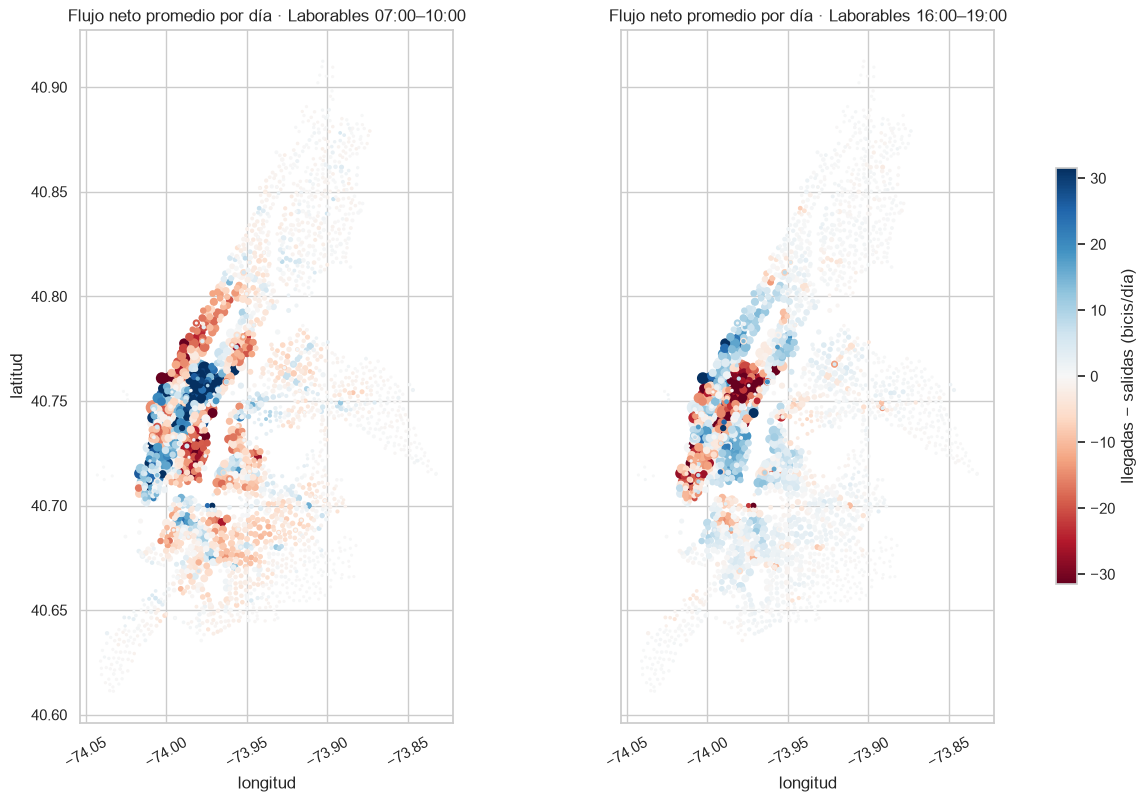

,name,neto_am,neto_pm,actividad_total
27,W 43 St & 10 Ave,-57.3,39.1,206523
66,E 10 St & Ave A,-44.9,28.9,157932
117,Riverside Blvd & W 67 St,-43.2,32.2,134398
103,W 44 St & 11 Ave,-42.4,24.7,138698
128,FDR Drive & E 35 St,-42.1,52.9,131654
94,E 2 St & Ave B,-41.7,17.2,144533
292,E 6 St & Ave B,-40.8,17.4,95283
344,Grand St & Samuel Dickstein Plaza,-40.8,17.1,86713


,name,neto_am,neto_pm,actividad_total
3,9 Ave & W 33 St,104.5,-100.6,272567
170,E 47 St & Park Ave,73.7,-73.8,118314
9,Broadway & W 25 St,64.0,-53.8,237854
693,Dock 72 Way & Market St,61.8,-58.5,44461
421,Greenwich St & Hubert St,60.9,-62.9,75844
95,North Moore St & Greenwich St,59.2,-90.3,144337
88,E 40 St & 5 Ave,54.5,-52.7,147823
19,1 Ave & E 68 St,53.5,-72.5,213572


In [19]:
laborable = (slots['dia_libre'] == 0).values
n_lab = slots.loc[laborable, 'fecha'].nunique()
def neto_ventana(h_ini, h_fin):
    m = laborable & slots['hora'].between(h_ini, h_fin - 1).values
    lle = Y[:, m, 2:].sum(axis=(1, 2)); sal = Y[:, m, :2].sum(axis=(1, 2))
    return (lle - sal) / max(n_lab, 1)

estaciones['neto_am'] = neto_ventana(7, 10)
estaciones['neto_pm'] = neto_ventana(16, 19)
lim = np.nanpercentile(np.abs(estaciones[['neto_am', 'neto_pm']].values), 98)

fig, axes = plt.subplots(1, 2, figsize=(16, 9), sharex=True, sharey=True)
for ax, col, tit in zip(axes, ['neto_am', 'neto_pm'], ['Laborables 07:00–10:00', 'Laborables 16:00–19:00']):
    sns.scatterplot(data=estaciones, x='lng', y='lat', hue=col, palette='RdBu', hue_norm=(-lim, lim),
                    size='actividad_total', sizes=(5, 120), ax=ax, legend=False, edgecolor='none')
    ax.set(title=f'Flujo neto promedio por día · {tit}', xlabel='longitud', ylabel='latitud'); ax.set_aspect(1.3)
    ax.tick_params(axis='x', rotation=30)
sm = plt.cm.ScalarMappable(cmap='RdBu', norm=plt.Normalize(-lim, lim))
fig.colorbar(sm, ax=axes, shrink=.6, label='llegadas − salidas (bicis/día)')
plt.show()

cols = ['name', 'neto_am', 'neto_pm', 'actividad_total']
print('🔴 Más se vacían en la mañana:'); display(estaciones.nsmallest(8, 'neto_am')[cols].round(1))
print('🔵 Más se llenan en la mañana:'); display(estaciones.nlargest(8, 'neto_am')[cols].round(1))

### 9.7 Mapa de densidad de demanda

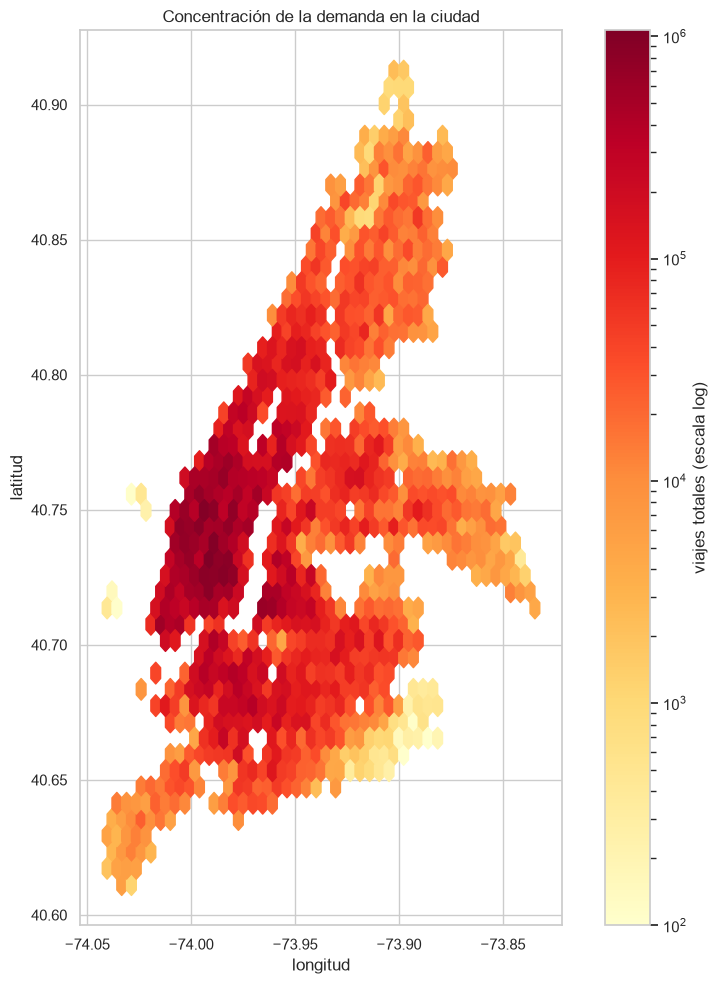

In [20]:
fig, ax = plt.subplots(figsize=(9, 10))
hb = ax.hexbin(estaciones['lng'], estaciones['lat'], C=estaciones['actividad_total'],
               reduce_C_function=np.sum, gridsize=45, cmap='YlOrRd', bins='log', mincnt=1)
fig.colorbar(hb, ax=ax, label='viajes totales (escala log)')
ax.set(title='Concentración de la demanda en la ciudad', xlabel='longitud', ylabel='latitud'); ax.set_aspect(1.3)
plt.tight_layout(); plt.show()

### 9.8 Impacto del clima

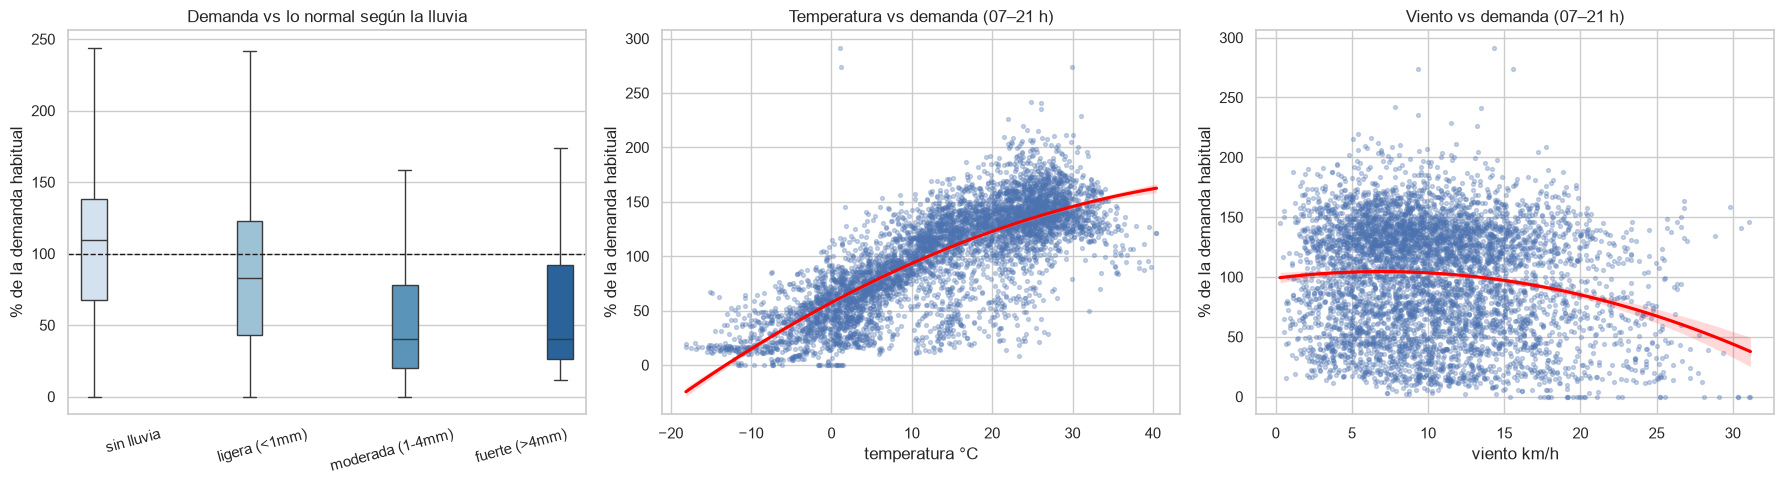

In [21]:
horario = ciudad.groupby(ciudad['timestamp'].dt.floor('h')).agg(
    salidas=('salidas', 'sum'), temperature_2m=('temperature_2m', 'mean'), precipitation=('precipitation', 'mean'),
    wind_speed_10m=('wind_speed_10m', 'mean'), hora=('hora', 'first'), dia_libre=('dia_libre', 'first'))
horario['lluvia'] = pd.cut(horario['precipitation'], [-0.01, 0.09, 1, 4, 1000],
                           labels=['sin lluvia', 'ligera (<1mm)', 'moderada (1-4mm)', 'fuerte (>4mm)'])
# para aislar el efecto del clima se compara contra el promedio de esa misma hora y tipo de día
base = horario.groupby(['hora', 'dia_libre'])['salidas'].transform('mean')
horario['vs_normal'] = horario['salidas'] / base * 100

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.boxplot(data=horario, x='lluvia', y='vs_normal', ax=axes[0], palette='Blues', hue='lluvia', legend=False, showfliers=False)
axes[0].axhline(100, color='k', ls='--', lw=1)
axes[0].set(title='Demanda vs lo normal según la lluvia', xlabel='', ylabel='% de la demanda habitual')
axes[0].tick_params(axis='x', rotation=15)
sns.regplot(data=horario[horario.hora.between(7, 21)], x='temperature_2m', y='vs_normal', ax=axes[1],
            scatter_kws=dict(s=8, alpha=.3), line_kws=dict(color='red'), order=2)
axes[1].set(title='Temperatura vs demanda (07–21 h)', xlabel='temperatura °C', ylabel='% de la demanda habitual')
sns.regplot(data=horario[horario.hora.between(7, 21)], x='wind_speed_10m', y='vs_normal', ax=axes[2],
            scatter_kws=dict(s=8, alpha=.3), line_kws=dict(color='red'), order=2)
axes[2].set(title='Viento vs demanda (07–21 h)', xlabel='viento km/h', ylabel='% de la demanda habitual')
plt.tight_layout(); plt.show()

### 9.9 Correlaciones
Se calculan sobre los totales de la ciudad por slot. Los objetivos se comparan contra el calendario y el clima. Ojo: la hora tiene una relación **no lineal** con la demanda (dos picos), por eso su correlación lineal es baja aunque sea la variable más importante. De ahí que en el modelo se codifique como embedding y con seno/coseno.

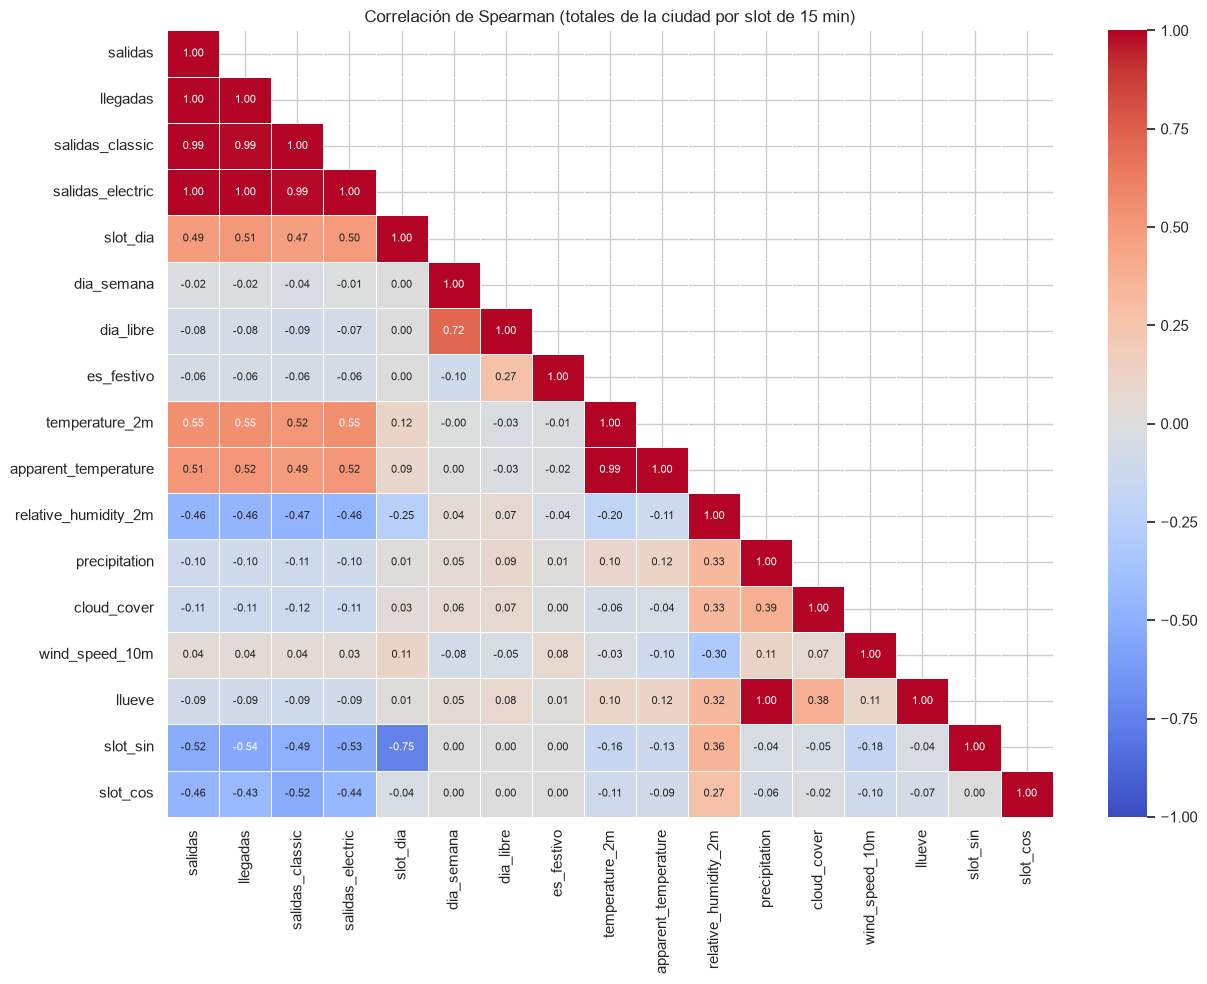

In [22]:
corr_cols = ['salidas', 'llegadas', 'salidas_classic', 'salidas_electric', 'slot_dia', 'dia_semana', 'dia_libre',
             'es_festivo', 'temperature_2m', 'apparent_temperature', 'relative_humidity_2m', 'precipitation',
             'cloud_cover', 'wind_speed_10m', 'llueve']
c_df = ciudad.assign(slot_sin=slots['slot_sin'], slot_cos=slots['slot_cos'])
corr = c_df[corr_cols + ['slot_sin', 'slot_cos']].corr(method='spearman')
fig, ax = plt.subplots(figsize=(13, 10))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1,
            ax=ax, annot_kws={'size': 8}, linewidths=.5)
ax.set_title('Correlación de Spearman (totales de la ciudad por slot de 15 min)')
plt.tight_layout(); plt.show()

### 9.10 Distribución de los conteos por estación y slot
Justifica la **Poisson loss**: la gran mayoría de los slots tienen 0, 1 o 2 bicis y la distribución es muy asimétrica.

salidas_total → media=0.557, varianza=2.015 (varianza > media indica sobre-dispersión)


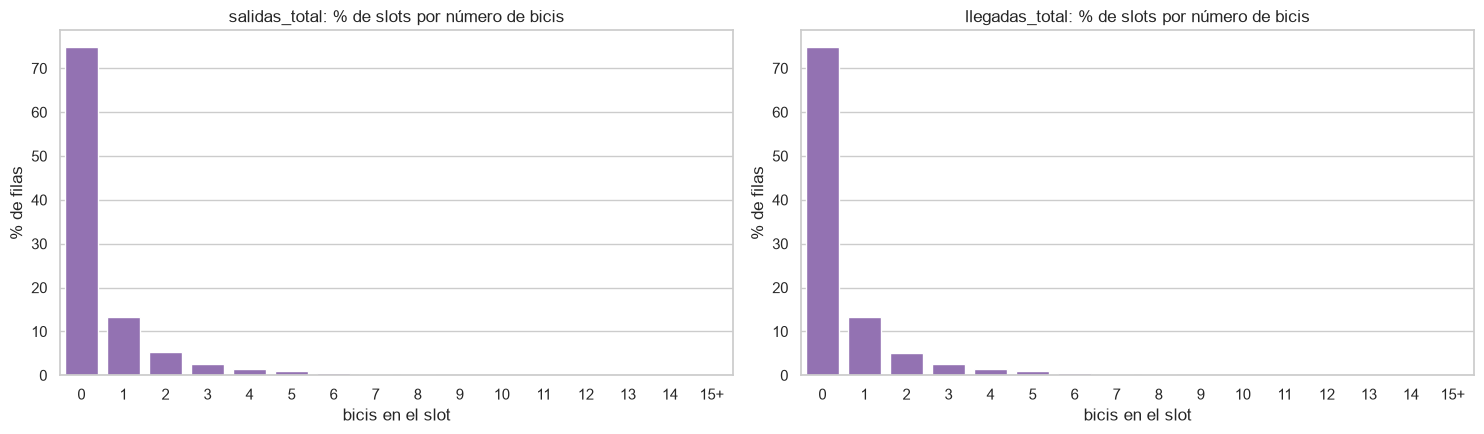

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, col in zip(axes, ['salidas_total', 'llegadas_total']):
    vc = demanda[col].clip(upper=15).value_counts(normalize=True).sort_index() * 100
    sns.barplot(x=vc.index.astype(str).str.replace('15', '15+'), y=vc.values, ax=ax, color='tab:purple')
    ax.set(title=f'{col}: % de slots por número de bicis', xlabel='bicis en el slot', ylabel='% de filas')
plt.tight_layout(); plt.show()

media, var = demanda['salidas_total'].mean(), demanda['salidas_total'].var()
print(f'salidas_total → media={media:.3f}, varianza={var:.3f} (varianza > media indica sobre-dispersión)')

### 9.11 Member vs casual (sólo contexto, no entra al modelo)

{'casual': 0.173, 'member': 0.827}


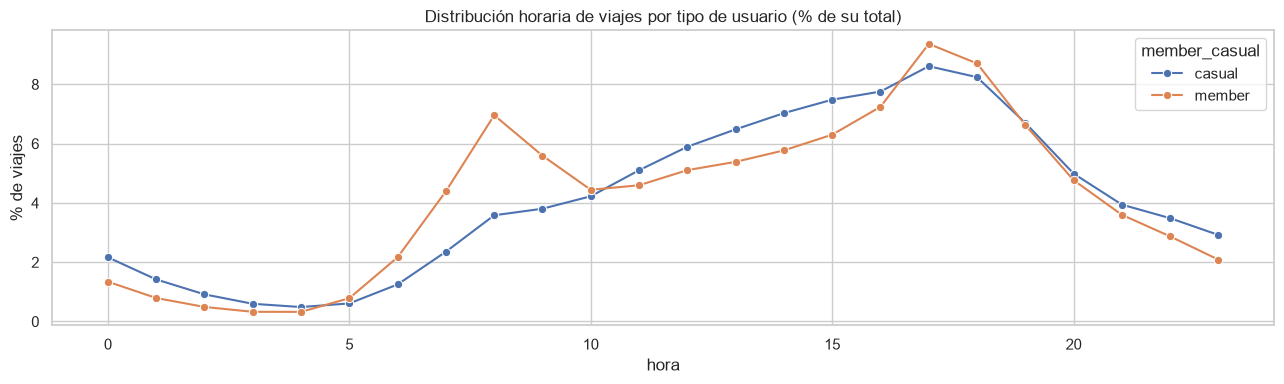

In [24]:
mc = (pd.DataFrame({'hora': CP['hora'].astype(int), 'member_casual': np.where(CP['miembro'] == 1, 'member', 'casual')})
        .groupby(['hora', 'member_casual']).size().rename('viajes').reset_index())
mc['pct'] = mc['viajes'] / mc.groupby('member_casual')['viajes'].transform('sum') * 100
fig, ax = plt.subplots(figsize=(13, 4))
sns.lineplot(data=mc, x='hora', y='pct', hue='member_casual', marker='o', ax=ax)
ax.set(title='Distribución horaria de viajes por tipo de usuario (% de su total)', ylabel='% de viajes')
plt.tight_layout(); plt.show()
print(mc.groupby('member_casual')['viajes'].sum().div(mc['viajes'].sum()).round(3).to_dict())


## 10. Resumen de la limpieza

,paso,filas,eliminadas,% del original
0,Original (todas las filas),45384105,0,100.00
1,Sin nulls ni vacíos,45228018,156087,99.66
2,Sólo classic_bike / electric_bike,45228018,0,99.66
3,ended_at > started_at,45227536,482,99.66
4,Duración ≤ 24 h,45227252,284,99.65
5,Coordenadas dentro de NYC,45227227,25,99.65
6,Sin estaciones de prueba / taller,45227224,3,99.65
7,Inicio dentro del periodo,45226627,597,99.65
8,Sin ride_id duplicados,45226146,481,99.65


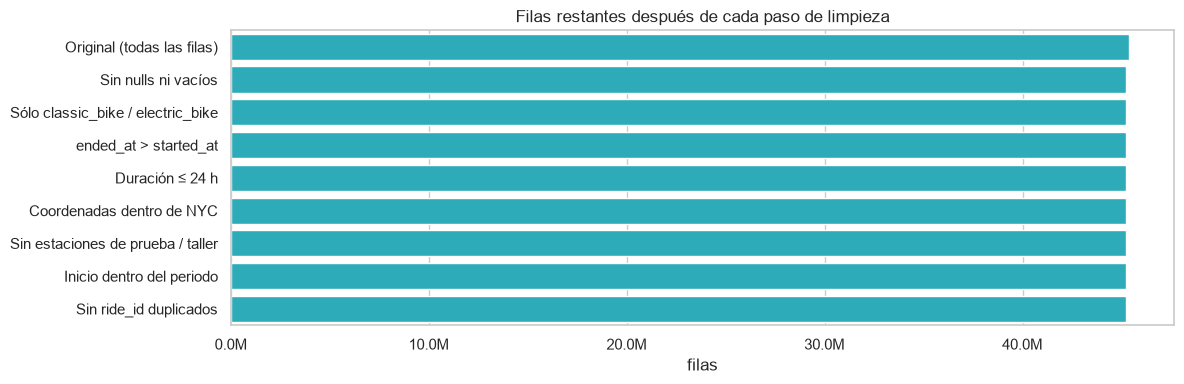

In [25]:
bit = pd.DataFrame(bitacora, columns=['paso', 'filas'])
bit['eliminadas'] = (-bit['filas'].diff()).fillna(0).astype(int)
bit['% del original'] = (bit['filas'] / FILAS_ORIGINALES * 100).round(2)
display(bit)

fig, ax = plt.subplots(figsize=(12, 4))
sns.barplot(data=bit, y='paso', x='filas', ax=ax, color='tab:cyan')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x / 1e6:.1f}M'))
ax.set(title='Filas restantes después de cada paso de limpieza', ylabel='', xlabel='filas')
plt.tight_layout(); plt.show()

## 11. Exportar los datos para el notebook 02

In [26]:
est_out = estaciones[['station_idx', 'station_id', 'name', 'lat', 'lng', 'salidas_total', 'llegadas_total',
                      'actividad_total', 'primer_dia', 'ultimo_dia', 'dias_activa', 'neto_am', 'neto_pm']]
est_out.to_parquet(OUT_DIR / 'estaciones.parquet', index=False)
slots.to_parquet(OUT_DIR / 'slots.parquet', index=False)
demanda.to_parquet(OUT_DIR / 'demanda_15min.parquet', index=False)

meta = dict(inicio=str(INICIO), fin=str(FIN), freq=FREQ, n_estaciones=int(N_EST), n_slots=int(N_SLOTS),
            filas_demanda=int(len(demanda)), targets=TARGETS, vars_clima=VARS_CLIMA,
            min_viajes_estacion=MIN_VIAJES_ESTACION, lat=NYC_LAT, lon=NYC_LON, tz=TZ)
pd.Series(meta).to_json(OUT_DIR / 'metadata.json', indent=2)

for f in sorted(OUT_DIR.iterdir()):
    print(f'{f.name:<30} {f.stat().st_size / 1e6:8.1f} MB')
print(f'\n✅ Listo: {N_EST:,} estaciones × {N_SLOTS:,} slots → {len(demanda):,} filas para el modelo')

clima_horario_raw.parquet           0.1 MB
demanda_15min.parquet             287.9 MB
estaciones.parquet                  0.2 MB
metadata.json                       0.0 MB
slots.parquet                       0.8 MB

✅ Listo: 2,515 estaciones × 35,040 slots → 81,158,880 filas para el modelo
